needs major updating (see k-means notetbooks)

# Fuzzy c-means clustering with training data

In this notebook, the fuzzy c-means algorithm is tested using signals generated with the Gilmore-akulichev model using the a range of frequencies and intensities. This is carried out to ensure that a single trained algorithm can be used to predict the stability of a range of cavitation signals measured under consistent conditions.

In [1]:
import sys

if sys.version_info[0] + 0.1 * sys.version_info[1] < 3.6:
    raise Exception("Must be using Python 3.6+ version")


import matplotlib.pyplot as plt

In [2]:
%matplotlib inline
sys.path.append("..")
import wavelet_transform.utils.training_data as train
import wavelet_transform.postprocess.plotting as plot
from wavelet_transform.utils.machine_learning import Cmeans
import wavelet_transform.wpt.inverse_transform as inv
from wavelet_transform.utils.preprocessing import preprocess

### Set pararmeters for bubble dynamics model
see bubble_dynamics_training_data.py

In [3]:
# Set sampling rate and noise std
sampling_rate = 50e6
std_noise = 0.05

# Set length of data to keep
sample_time = 20 / 1.5e6
data_len = int(sample_time * sampling_rate)

# Parameters for the wavelet transform
wavelet = "db4"
levels = None  # max level for the transform
mode = "symmetric"
use_min_entropy = True
min_level = 3

freq_threshold = 15e6 / (sampling_rate / 2)

window_data = False  # whether to window the data during preprocessing or not

### Training data

Run bubble dynamics over a range of frequencies and intensities to generate a larger array of training data.

In [4]:
wpt_df = train.generate_training_data_with_wavelet(
    wavelet,
    sampling_rate,
    levels,
    mode,
    std_noise,
    min_entropy=use_min_entropy,
    min_level=min_level,
    freq_threshold=freq_threshold,
    window=window_data
)

### Training

Train fuzzy c-means on the generated data

In [5]:
# Feature selection
classifying_metrics = [
    "average energy",
    "kurtosis",
    # "crest factor",
    # "log average energy",
    # "level entropy",
    "spectral entropy",
    # "skewness"
]

# Parameters for fuzzy c-means
n_clusters = 5
m = 2

cmeans = Cmeans()

In [6]:
data_train, labels, _, centers, *_ = cmeans.train(
    wpt_df, n_clusters, classifying_metrics, m
)

### Clustering results

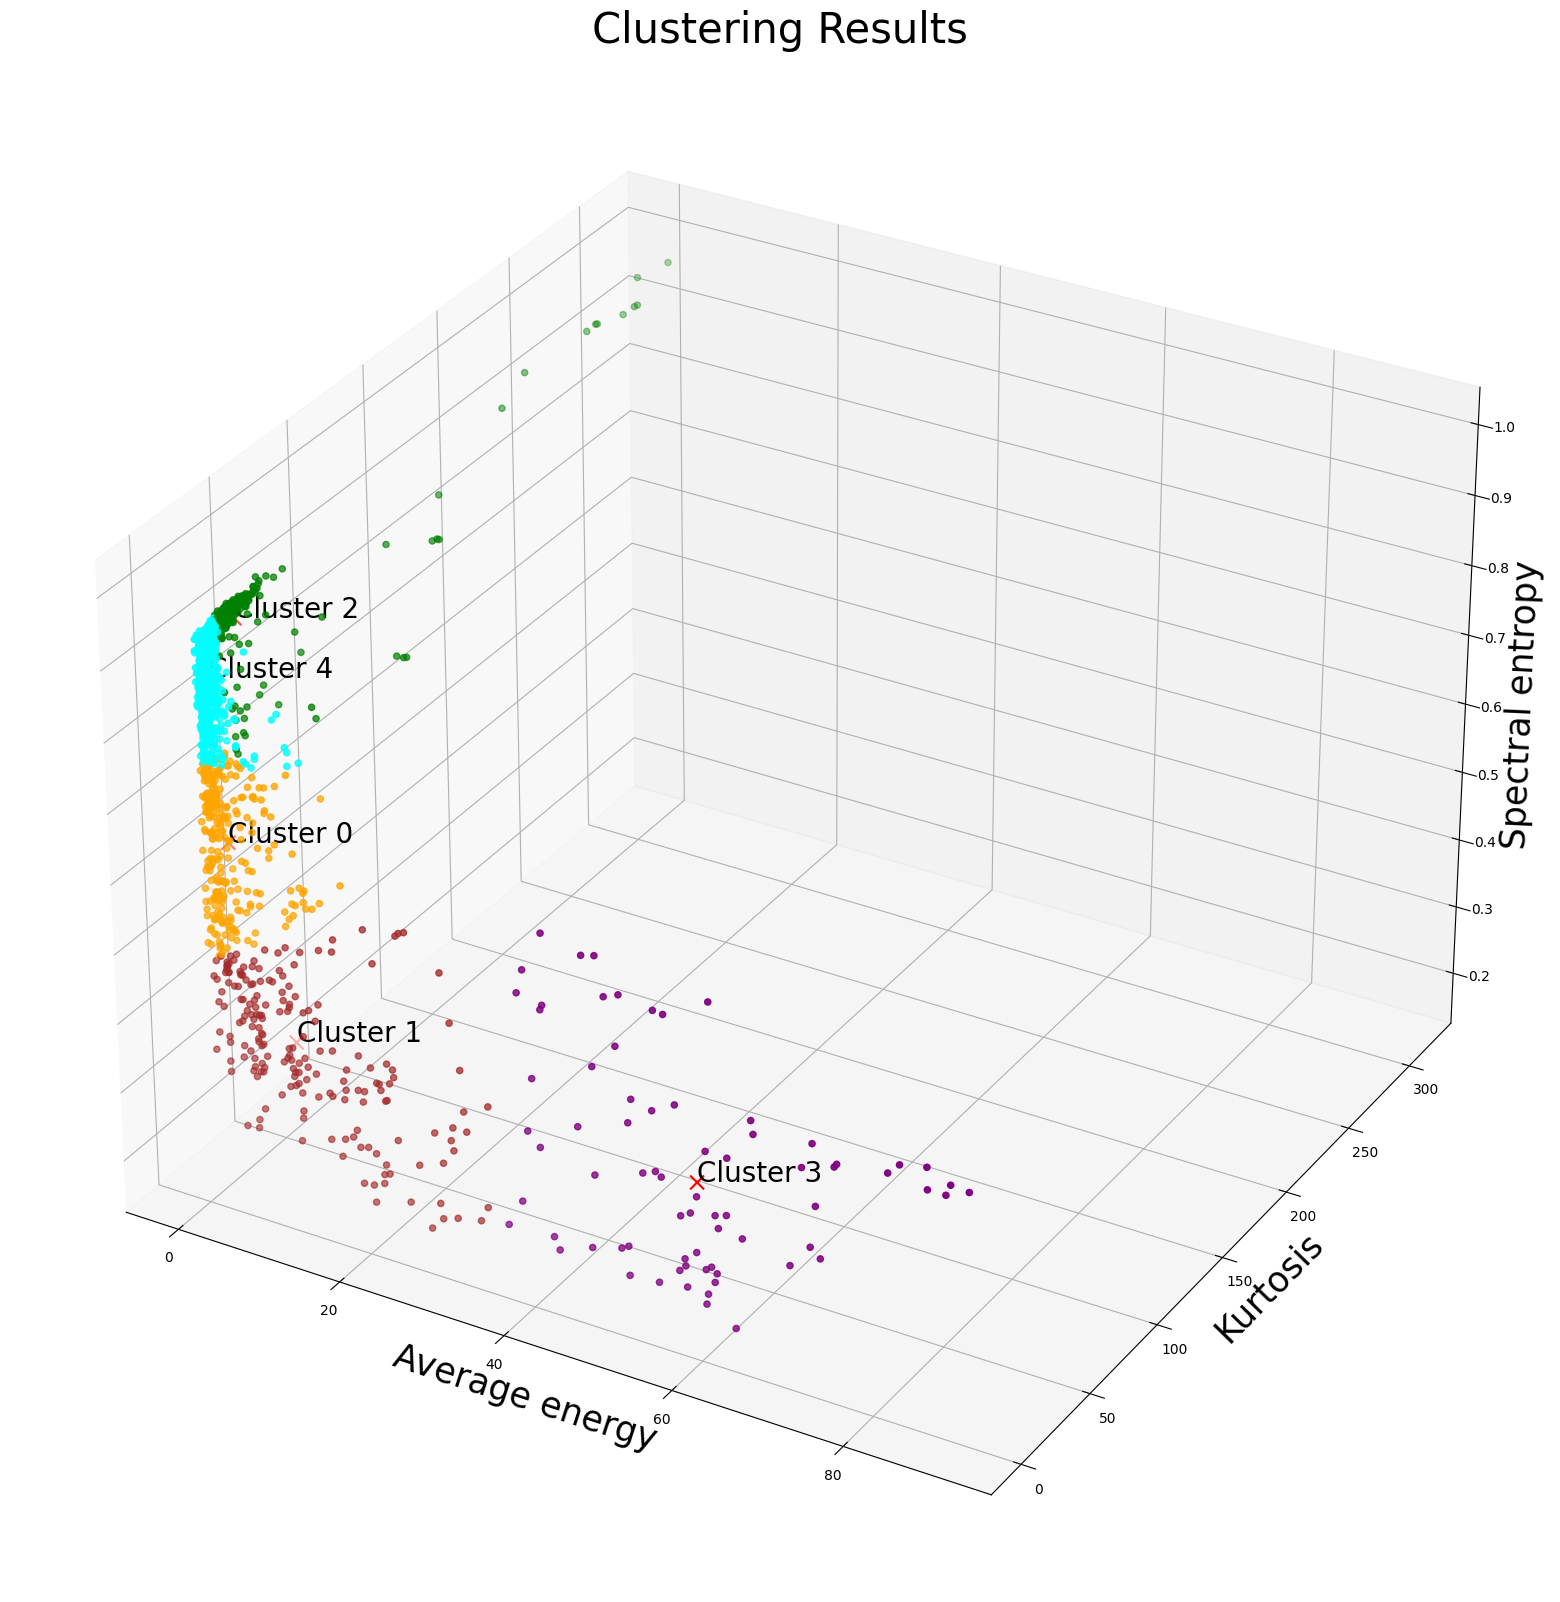

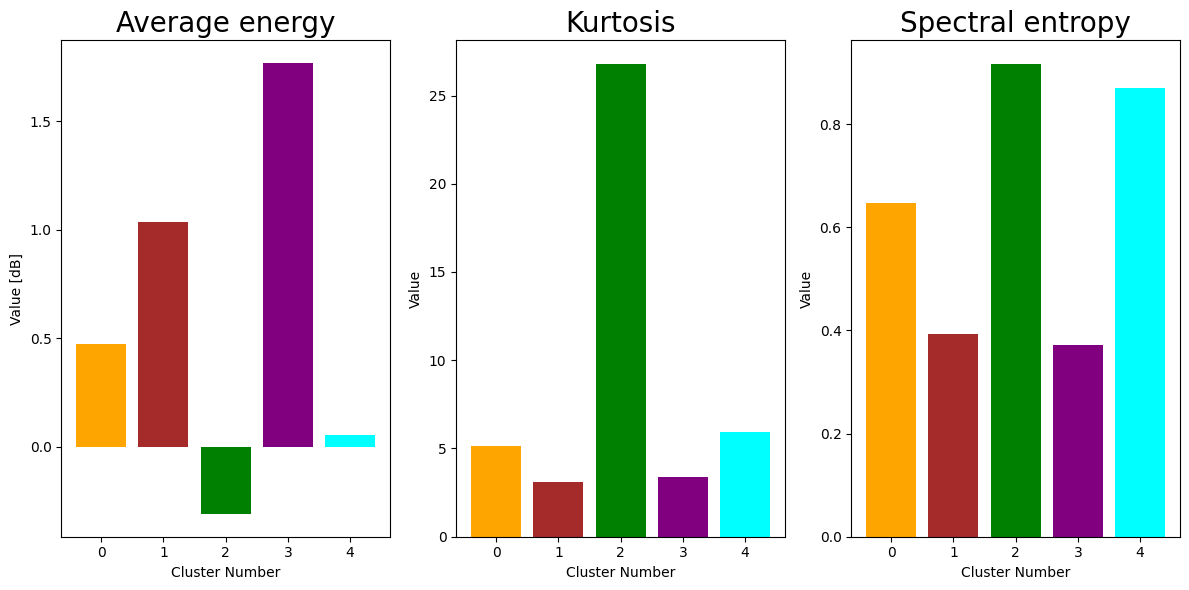

In [7]:
fig = plot.plot_clustering(data_train, centers, labels)

# Plot centroid metrics
fig = plot.plot_centers(classifying_metrics, centers)

### Numerical studies

In [8]:
wavelets = [f"db{i}" for i in range(4, 21)]

In [9]:
run = False
if run is True:
    from sklearn.metrics import silhouette_score
    scores = []

    for wavelet in wavelets:
        print(wavelet)
        cmeans_ = Cmeans()
        wpt_df = train.generate_training_data_with_wavelet(wavelet, sampling_rate, levels, mode, std_noise, data_len)
        _, _labels, _data_train_normalised, *_   = cmeans_.train(wpt_df, n_clusters=n_clusters, m=m)
        scores.append(silhouette_score(_data_train_normalised, _labels)) 
        
    fig, ax = plt.subplots()
    fig.set_size_inches(15, 7)
    plt.bar(wavelets, scores)
    plt.title("silhouette score vs db order")
    plt.show()

### Classifying new data points

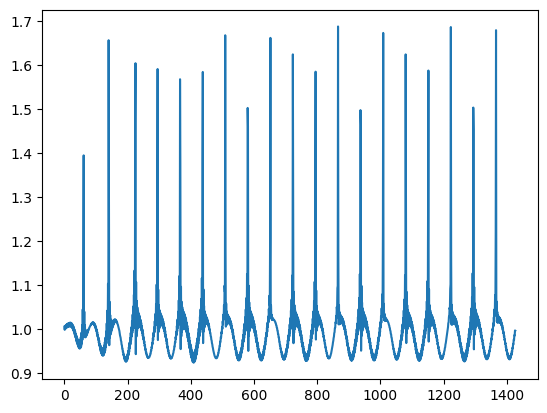

In [10]:
frequency = 7E5
pac = -2E5
R_init = 3e-6

min_energy = 0  # Only nodes with energy at least min_energy * total_energy will be considered

data = train.get_data(R_init, frequency, pac, sampling_rate)
data_processed = preprocess(data, window=window_data)

new_wpt_df, new_tr_obj = train.generate_training_data(
    data_processed, levels, wavelet, mode, 
    include_tr_obj=True, min_entropy=use_min_entropy,
    min_level=min_level, freq_threshold=freq_threshold
)

new_wpt_df.head()

plt.plot(data)
plt.show()

In [11]:
new_labels, new_membership_matrix, _ = cmeans.test(new_wpt_df[classifying_metrics])

### Reconstructing by cluster

In [12]:
# Sum all reconstructions belonging to the same group
plot.plot_reconstructions_by_group(new_tr_obj, new_labels, n_clusters)

### Plot nodes

Plot each node in the test data set alongside its membership values. Filter by the centre the node is assigned to.

In [13]:
run = True
if run is True:
    plot_centres = [2]
    for i, (node, assignment) in enumerate(zip(new_tr_obj.get_leaf_nodes(), new_labels)):
        if assignment in plot_centres:
            rec = inv.inv_dwpt(new_tr_obj, node.level, nodes=node)
            plt.plot(rec)
            plt.title(f"memberships {new_membership_matrix[i]}")
            plt.show()
